---
title: Plotting a Single Day (One Time Step)
authors:
  - alex_dunne
downloads:
  - file: ./beginners_guide.zip
    title: Download the guide (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/beginners_guide/section4.png?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-beginners_guide)	­

In this section we are going to plot some of the Himawari data we looked at before, for the variable cloud type. 
Before plotting, we need to select a single time step from the dataset. `xarray` gives us two ways to do this.

In [6]:
import xarray as xr         # NetCDF & multi-dimensional data
import matplotlib.pyplot as plt  # plotting
from glob import glob        #global path directory

In [ ]:
# Download the data, it can take a few minutes
!python download_data.py

## Select a time step

In [ ]:
files = glob("data/IDE*.nc")

ds = xr.open_mfdataset(files, combine="nested")

ds

In [8]:
# let's have a look at cloud type!
# By integer position (first time step)
da_step = ds["cloud_type"].isel(time=1) # this selects the first available timestep

:::{note} `.isel()` `.isel(time=0)`
Select by integer index — like list[0]. Use this when you want 'the first', 'the last', or 'the Nth' element regardless of what label it has.
:::

:::{note} `sel()` `.sel(time="2015-11-03")`
Select by label value — the actual date, coordinate, or name. Use this when you know which date or location you want.
:::

In [9]:
# By label (a specific date/time)
da_step = ds["cloud_type"].sel(time="2024-12-31T19:00:00")

print(da_step)

<xarray.DataArray 'cloud_type' (latitude: 1726, longitude: 2214)> Size: 15MB
dask.array<getitem, shape=(1726, 2214), dtype=float32, chunksize=(20, 2214), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float32 7kB -44.5 -44.48 -44.46 ... -10.02 -10.0
  * longitude  (longitude) float32 9kB 112.0 112.0 112.0 ... 156.2 156.2 156.3
    time       datetime64[ns] 8B 2024-12-31T19:00:00
Attributes:
    long_name:      Cloud type
    flag_meanings:  clear low medium high high_thin
    flag_values:    [0 5 6 7 8]
    grid_mapping:   crs
    comment:        Cloud type retrieved from corresponding satellite observa...


## Plot the selected time step

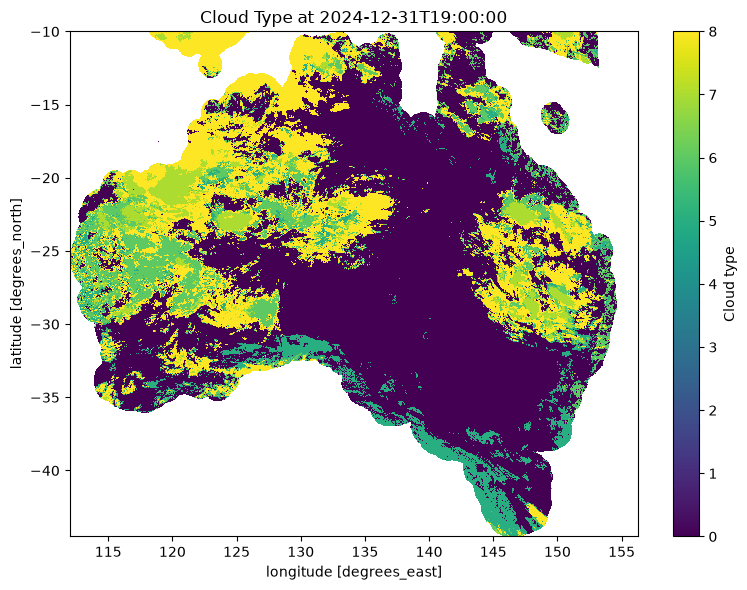

In [10]:
# Plot
plt.figure(figsize=(8, 6))
da_step.plot()
plt.title('Cloud Type at 2024-12-31T19:00:00')
plt.tight_layout()
plt.show()

:::{note} `plt.subplots()` `fig, ax = plt.subplots(figsize=(10, 4))`
Creates a figure and axes object. Always use this pattern — it gives you full control over labels, titles, and styling compared to calling plt.plot() directly.
:::

## A tried and true plotting script for all your future needs!

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- USER INPUT ---
FILE = "file_path"   # add your file path
VAR  = "variable_name"   # variable to plot
TIME = "time_select"   # timestep to plot
# -------------------

# Load dataset
ds = xr.open_dataset(FILE)

# Select timestep
da = ds[VAR].sel(time=TIME)

# Plot Set Up
ax = plt.axes(projection=ccrs.PlateCarree())
plt.figure(figsize=(8, 6))

# Call your data
da.plot(ax=ax, transform=ccrs.PlateCarree(),cmap="viridis")

# Add geographic context
ax.coastlines(resolution="10m", linewidth=1.0)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.add_feature(cfeature.STATES, linewidth=0.6)

# Labels + title
ax.set_title(f"{VAR} at {TIME}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()